# Sleep–Wake Segmentation and Awakening Forecasting from EEG

**CS495 Deep Learning**

The shared PyTorch model estimates the sleep state at every completed 30-second EEG epoch and predicts a probability distribution over the time to the next sustained awakening. A qualifying awakening starts when scored Sleep transitions to at least four consecutive 30-second Wake epochs.

Open this notebook in Colab and place `sleep_edf_wake_data.npz` in `/content`, or point `ARCHIVE_PATH` below to its location. If you run the original `Sleep_EDF_Wake_Up_Prediction_Colab.ipynb` first, its default export directory is detected automatically. Colab’s standard Python environment includes the dependencies. A GPU runtime speeds up training, and the same cells run on CPU. The complete training and evaluation code is included below.

[Sleep-EDF Database Expanded on PhysioNet](https://physionet.org/content/sleep-edfx/1.0.0/)


In [1]:
from pathlib import Path

ARCHIVE_PATH = Path("sleep_edf_wake_data.npz")
if not ARCHIVE_PATH.is_file():
    colab_export = Path("/content/sleep_edf_wakeup/sleep_edf_wake_data.npz")
    if colab_export.is_file():
        ARCHIVE_PATH = colab_export

OUTPUT_DIR = Path("artifacts")
MAX_EPOCHS = 20
BATCH_SIZE = 512
SEED = 495

if not ARCHIVE_PATH.is_file():
    raise FileNotFoundError(
        "Upload sleep_edf_wake_data.npz, set ARCHIVE_PATH, or run the supplied preprocessing notebook first."
    )
print(f"Archive: {ARCHIVE_PATH}")

Archive: sleep_edf_wake_data.npz


## 1. Validate the archive and build task inputs

- **Detection.** `X_state` contains one 11-feature vector per scored epoch and `y_state` uses Wake = 0, Sleep = 1. Sort by recording ID and epoch-end timestamp, split at recording boundaries or any jump other than 30 seconds, and slide a 10-row window within each uninterrupted run. Train with all ten epoch labels in each window. Both Wake-ending and Sleep-ending windows are required in each split.
- **Forecasting.** `X_forecast` already has shape `(N, 10, 11)`. Verify every window against the matching `X_state` history and its Sleep endpoint. The target is `floor(y_forecast_min / 5)`. Observed classes 0–11 are half-open 5-minute bins from `[0, 5)` through `[55, 60)`. Class 12 represents a capped target of 60 minutes and uses onset sentinel `-1`. Check each target against the absolute Wake onset timestamp and the four consecutive Wake labels after the transition. A delay of zero means the first Wake epoch starts exactly when the last input epoch ends.
- **Splits and scaling.** Preserve the archive’s subject assignments across both heads. Compute one mean and population standard deviation per feature from the unique training `X_state` rows. Use those 11 means and scales on both tasks, on every split, and in the demo.

The supplied preprocessing extracts five log band powers, five relative band powers, and log RMS from EEG Fpz-Cz, using samples within each completed epoch. Filtering within the epoch can use all 30 seconds because each prediction is made at the epoch’s end. Annotations determine labels and which archive rows are available, and the model receives EEG features as input.


In [2]:
from dataclasses import dataclass
from pathlib import Path

import numpy as np
from numpy.lib.stride_tricks import sliding_window_view


EPOCH_SEC = 30
HISTORY = 10
N_FEATURES = 11
N_CLASSES = 13
SPLITS = ("train", "validation", "test")
BANDS = ("delta", "theta", "alpha", "sigma", "beta")
FEATURE_NAMES = tuple(f"{band}_{kind}_power" for kind in ("log", "relative") for band in BANDS) + (
    "log_rms",
)
CLASS_LABELS = tuple(f"{i * 5}–{(i + 1) * 5} min" for i in range(12)) + ("No onset <60 min",)


@dataclass
class EEGData:
    arrays: dict[str, np.ndarray]
    state_runs: list[np.ndarray]
    state_windows: dict[str, np.ndarray]
    forecast_classes: np.ndarray


def require(condition, message):
    if not condition:
        raise ValueError(message)


def load_archive(path: str | Path, verbose: bool = True) -> EEGData:
    with np.load(path, allow_pickle=False) as archive:
        a = {key: archive[key] for key in archive.files}
    if verbose:
        print("Archive keys, shapes, and data types")
        for key, value in a.items():
            print(f"  {key:38} {str(value.shape):17} {value.dtype}")

    metadata = {
        "schema_version": 1, "epoch_sec": EPOCH_SEC, "history_epochs": HISTORY,
        "wake_minimum_sec": 120, "horizon_min": 60, "sampling_hz": 100,
        "channel": "EEG Fpz-Cz",
    }
    for key, expected in metadata.items():
        require(key in a and a[key].shape == () and a[key].item() == expected,
                f"Expected archive metadata {key}={expected!r}.")
    require(tuple(a.get("feature_names", ())) == FEATURE_NAMES, "Unexpected feature names or order.")

    record_ids = a["record_id"]
    subjects = a["record_subject_id"]
    splits = a["record_split"]
    require(record_ids.ndim == 1 and subjects.shape == splits.shape == record_ids.shape,
            "Manifest identifiers must be aligned one-dimensional arrays.")
    require(len(np.unique(record_ids)) == len(record_ids), "Duplicate manifest recording ID.")
    require(set(splits) == set(SPLITS), "Missing or unexpected manifest split.")
    subject_sets = {split: set(subjects[splits == split]) for split in SPLITS}
    require(sum(map(len, subject_sets.values())) == len(set(subjects)), "A subject crosses the splits.")
    manifest = dict(zip(record_ids, zip(subjects, splits)))

    for task, target, feature_shape in (
        ("state", "y_state", (N_FEATURES,)),
        ("forecast", "y_forecast_min", (HISTORY, N_FEATURES)),
    ):
        y = a[target]
        x = a[f"X_{task}"]
        require(y.ndim == 1 and x.shape == (len(y), *feature_shape) and np.isfinite(x).all(),
                f"Unexpected {task} feature shape or nonfinite value.")
        record, subject, split, end = (a[f"{task}_{field}"] for field in (
            "record_id", "subject_id", "split", "epoch_end_sec",
        ))
        require(all(arr.shape == y.shape for arr in (record, subject, split, end)),
                f"Misaligned {task} metadata.")
        require(set(split) == set(SPLITS), f"Missing or unexpected {task} split.")
        require(end.dtype.kind in "iu" and np.all((end > 0) & (end % EPOCH_SEC == 0)),
                f"Invalid {task} epoch-end timestamps.")
        for recording in np.unique(record):
            rows = record == recording
            require(recording in manifest, f"Unknown recording {recording}.")
            expected_subject, expected_split = manifest[recording]
            require(np.all(subject[rows] == expected_subject) and np.all(split[rows] == expected_split),
                    f"Manifest disagrees with {task} rows for {recording}.")
            require(len(np.unique(end[rows])) == rows.sum(), f"Duplicate {task} epoch for {recording}.")

    require(set(a["state_record_id"]) == set(record_ids), "State rows do not cover the manifest.")
    require(np.isin(a["y_state"], [0, 1]).all(), "State labels must be Wake=0 or Sleep=1.")
    classes = forecast_targets(a)
    runs, windows = build_state_windows(a)
    validate_forecast_histories(a)
    data = EEGData(a, runs, windows, classes)
    if verbose:
        print(f"\n{len(record_ids)} recordings / {len(np.unique(subjects))} people; disjoint subject splits")
        print("Counts in order Wake, Sleep for state and class 0 through 12 for forecast")
        for split in SPLITS:
            state = a["state_split"] == split
            forecast = a["forecast_split"] == split
            endpoints = a["y_state"][windows[split][:, -1]]
            print(f"{split}: {len(subject_sets[split])} people, {int((splits == split).sum())} recordings")
            print(f"  State epochs {state.sum():,}: {np.bincount(a['y_state'][state].astype(int), minlength=2)}")
            print(f"  State 10-epoch windows {len(endpoints):,}, by end label: "
                  f"{np.bincount(endpoints.astype(int), minlength=2)}")
            print(f"  Forecast windows {forecast.sum():,}: {np.bincount(classes[forecast], minlength=N_CLASSES)}")
        print("Verified every forecast history, target bin, onset sentinel, and observed sustained Wake.")
    return data


def forecast_targets(a):
    minutes = a["y_forecast_min"]
    end = a["forecast_epoch_end_sec"]
    onset = a["forecast_wake_onset_sec"]
    require(onset.shape == minutes.shape and onset.dtype.kind in "iu", "Invalid forecast onset array.")
    require(np.isfinite(minutes).all() and np.all((minutes >= 0) & (minutes <= 60)),
            "Forecast minutes must be in [0, 60].")
    require(np.all(end >= HISTORY * EPOCH_SEC), "Forecast history starts before the recording.")
    observed = onset >= 0
    delta = onset[observed].astype(np.int64) - end[observed].astype(np.int64)
    require(np.all((delta >= 0) & (delta < 3600) & (delta % EPOCH_SEC == 0)),
            "Observed onsets must be on the epoch grid and before 60 minutes.")
    require(np.all(onset[~observed] == -1) and np.all(minutes[~observed] == 60),
            "Capped targets must have sentinel -1 and target 60 minutes.")
    np.testing.assert_allclose(minutes[observed], delta / 60, rtol=0, atol=1e-6)
    classes = np.floor_divide(minutes, 5).astype(np.int64)
    expected = np.full(len(minutes), N_CLASSES - 1, dtype=np.int64)
    expected[observed] = delta // 300
    np.testing.assert_array_equal(classes, expected)
    return classes


def build_state_windows(a):
    record, end, split = (a[f"state_{field}"] for field in ("record_id", "epoch_end_sec", "split"))
    ordered = np.lexsort((end, record))
    boundaries = (record[ordered[1:]] != record[ordered[:-1]]) | (np.diff(end[ordered]) != EPOCH_SEC)
    runs = np.split(ordered, np.flatnonzero(boundaries) + 1)
    grouped = {name: [] for name in SPLITS}
    for run in runs:
        if len(run) >= HISTORY:
            grouped[split[run[0]]].append(sliding_window_view(run, HISTORY))
    windows = {name: np.concatenate(parts) if parts else np.empty((0, HISTORY), dtype=np.int64)
               for name, parts in grouped.items()}
    for name, indices in windows.items():
        require(np.all(record[indices] == record[indices[:, :1]])
                and np.all(np.diff(end[indices], axis=1) == EPOCH_SEC)
                and np.all(split[indices] == name), f"An invalid {name} state window was constructed.")
        require(set(a["y_state"][indices[:, -1]]) == {0, 1},
                f"The {name} state windows must end on both Wake and Sleep epochs.")
    return runs, windows


def validate_forecast_histories(a):
    """Compare archived histories and check that observed onsets have four Wake epochs."""
    for record in np.unique(a["forecast_record_id"]):
        state = np.flatnonzero(a["state_record_id"] == record)
        state = state[np.argsort(a["state_epoch_end_sec"][state])]
        times = a["state_epoch_end_sec"][state]
        labels = a["y_state"][state]
        rows = np.flatnonzero(a["forecast_record_id"] == record)
        end = a["forecast_epoch_end_sec"][rows]
        positions = np.searchsorted(times, end)[:, None] - np.arange(HISTORY - 1, -1, -1)
        require(np.all((positions >= 0) & (positions < len(times))), f"Missing forecast history in {record}.")
        np.testing.assert_array_equal(times[positions], end[:, None] - EPOCH_SEC * np.arange(HISTORY - 1, -1, -1))
        require(np.all(labels[positions[:, -1]] == 1), f"A forecast history ends on Wake in {record}.")
        np.testing.assert_allclose(a["X_forecast"][rows], a["X_state"][state[positions]], rtol=1e-6, atol=1e-7)

        onset = a["forecast_wake_onset_sec"][rows]
        scored_times = sliding_window_view(times, 5)
        scored_labels = sliding_window_view(labels, 5)
        transitions = (np.diff(scored_times, axis=1) == EPOCH_SEC).all(axis=1) & (
            scored_labels == [1, 0, 0, 0, 0]
        ).all(axis=1)
        # The preceding sleep epoch ends exactly at the first Wake epoch's start.
        wake_starts = np.append(scored_times[transitions, 0].astype(np.int64), np.iinfo(np.int64).max)
        next_wake = wake_starts[np.searchsorted(wake_starts, end)]
        expected = np.where(next_wake - end < 3600, next_wake, -1)
        np.testing.assert_array_equal(onset, expected, err_msg=f"Sustained Wake mismatch in {record}")


def evaluation_histories(data, split):
    """One row per scored epoch, using the longest available causal history up to 10."""
    a = data.arrays
    windows, positions, rows = [], [], []
    for run in data.state_runs:
        if a["state_split"][run[0]] != split:
            continue
        end = np.arange(len(run))
        start = np.maximum(end - HISTORY + 1, 0)
        lookup = start[:, None] + np.arange(HISTORY)
        observed = lookup <= end[:, None]
        # A safe index for gathering. The unused suffix is zeroed after scaling.
        windows.append(run[np.minimum(lookup, end[:, None])])
        positions.append(end - start)
        rows.append(run)
    indices = np.concatenate(windows)
    last = np.concatenate(positions)
    targets = np.concatenate(rows)
    np.testing.assert_array_equal(np.sort(targets), np.flatnonzero(a["state_split"] == split))
    np.testing.assert_array_equal(indices[np.arange(len(targets)), last], targets)
    return indices, last, targets


def fit_normalization(data):
    a = data.arrays
    train = a["X_state"][a["state_split"] == "train"].astype(np.float64)
    mean = train.mean(axis=0)
    scale = train.std(axis=0)
    scale[scale < 1e-8] = 1.0
    return mean.astype(np.float32), scale.astype(np.float32)


def normalize(x, mean, scale):
    return (np.asarray(x, dtype=np.float32) - mean) / scale

In [3]:
data = load_archive(ARCHIVE_PATH)
require(len(data.arrays["record_id"]) == 153 and len(set(data.arrays["record_subject_id"])) == 78,
        "The full project archive must contain 153 recordings from 78 people.")

Archive keys, shapes, and data types
  X_state                                (195469, 11)      float32
  y_state                                (195469,)         int8
  state_record_id                        (195469,)         <U6
  state_subject_id                       (195469,)         <U5
  state_epoch_end_sec                    (195469,)         int32
  state_split                            (195469,)         <U10
  X_forecast                             (29771, 10, 11)   float32
  y_forecast_min                         (29771,)          float32
  forecast_record_id                     (29771,)          <U6
  forecast_subject_id                    (29771,)          <U5
  forecast_epoch_end_sec                 (29771,)          int32
  forecast_wake_onset_sec                (29771,)          int32
  forecast_split                         (29771,)          <U10
  feature_names                          (11,)             <U20
  sampling_hz                            ()                

## 2. Shared causal CNN–Transformer

| Operation | Tensor shape | Role |
|---|---|---|
| EEG feature window | `(B, 10, 11)` | 10 epochs, oldest to newest |
| Channel-first convolution input after padding | `(B, 11, 12)` | Add two zeros on the left for the width-3 kernel |
| Convolution, GELU, transpose | `(B, 10, 64)` | Preserve all ten positions |
| Learned positions and two encoder layers | `(B, 10, 64)` | Four attention heads of width 16 and a position-wise `64 → 128 → 64` feed-forward network in each layer |
| Sleep–wake head | `(B, 10)` | One logit per epoch, with sigmoid at inference |
| Awakening head | `(B, 13)` | One vector from the last embedding, with softmax at inference |

The width-3 convolution reads positions `t−2`, `t−1` and `t`, using zeros when a position precedes the window. The attention mask allows query position `t` to attend to keys `j ≤ t`. PyTorch’s scaled dot-product attention applies this lower-triangular rule through `is_causal=True`. Each attention and feed-forward sublayer uses layer normalization and a residual connection. Layer normalization acts on features at each position.

The causality check perturbs the suffix after each of the first nine positions in evaluation mode and compares earlier sleep logits. It also compares the prefix predictions and the forecast evaluated at that prefix endpoint. The training cell repeats the check after reloading the selected checkpoint.


In [4]:
from pathlib import Path

import numpy as np
import torch
from torch import nn
from torch.nn import functional as F



class CausalEncoderLayer(nn.Module):
    def __init__(self, width=64, heads=4, feedforward=128, dropout=0.1):
        super().__init__()
        self.heads = heads
        self.head_width = width // heads
        self.dropout = dropout
        self.attn_norm = nn.LayerNorm(width)
        self.qkv = nn.Linear(width, 3 * width)
        self.attn_out = nn.Linear(width, width)
        self.ff_norm = nn.LayerNorm(width)
        self.ff = nn.Sequential(
            nn.Linear(width, feedforward), nn.GELU(), nn.Dropout(dropout), nn.Linear(feedforward, width),
        )
        self.residual_dropout = nn.Dropout(dropout)

    def forward(self, x):
        batch, steps, width = x.shape
        qkv = self.qkv(self.attn_norm(x)).reshape(batch, steps, 3, self.heads, self.head_width)
        q, k, v = qkv.permute(2, 0, 3, 1, 4).unbind(0)
        attention = F.scaled_dot_product_attention(
            q, k, v, is_causal=True, dropout_p=self.dropout if self.training else 0.0,
        )
        attention = attention.transpose(1, 2).reshape(batch, steps, width)
        x = x + self.residual_dropout(self.attn_out(attention))
        return x + self.residual_dropout(self.ff(self.ff_norm(x)))


class SleepWakeModel(nn.Module):
    def __init__(self, dropout=0.1):
        super().__init__()
        width = 64
        kernel = 3
        self.left_padding = kernel - 1
        self.conv = nn.Conv1d(N_FEATURES, width, kernel_size=kernel)
        self.position = nn.Embedding(HISTORY, width)
        self.encoder = nn.Sequential(*(CausalEncoderLayer(dropout=dropout) for _ in range(2)))
        self.final_norm = nn.LayerNorm(width)
        self.state_head = nn.Linear(width, 1)
        self.forecast_head = nn.Linear(width, N_CLASSES)

    def encode(self, x):
        if x.ndim != 3 or x.shape[-1] != N_FEATURES or not 1 <= x.shape[1] <= HISTORY:
            raise ValueError(f"Expected (batch, 1 to {HISTORY}, {N_FEATURES}) EEG features.")
        x = F.pad(x.transpose(1, 2), (self.left_padding, 0))
        x = F.gelu(self.conv(x)).transpose(1, 2)
        x = x + self.position(torch.arange(x.shape[1], device=x.device))
        return self.final_norm(self.encoder(x))

    def forward(self, x):
        embeddings = self.encode(x)
        state_logits = self.state_head(embeddings).squeeze(-1)
        forecast_logits = self.forecast_head(embeddings[:, -1, :])
        return state_logits, forecast_logits


@torch.inference_mode()
def verify_causality(model, x):
    """Perturb each possible suffix and compare untouched prefix predictions."""
    was_training = model.training
    model.eval()
    try:
        state, forecast = model(x)
        embeddings = model.encode(x)
        assert embeddings.shape == (len(x), HISTORY, 64)
        assert state.shape == (len(x), HISTORY) and forecast.shape == (len(x), N_CLASSES)
        max_change = 0.0
        for cut in range(1, HISTORY):
            modified = x.clone()
            modified[:, cut:] = -7.0 * x[:, cut:] + 3.0
            changed, _ = model(modified)
            torch.testing.assert_close(state[:, :cut], changed[:, :cut], rtol=1e-5, atol=1e-5)
            max_change = max(max_change, (state[:, :cut] - changed[:, :cut]).abs().max().item())
            prefix_state, prefix_forecast = model(x[:, :cut])
            torch.testing.assert_close(state[:, :cut], prefix_state, rtol=1e-5, atol=1e-5)
            torch.testing.assert_close(
                model.forecast_head(embeddings[:, cut - 1]), prefix_forecast, rtol=1e-5, atol=1e-5,
            )
        return max_change
    finally:
        model.train(was_training)


def load_checkpoint(path: str | Path, device="cpu"):
    payload = torch.load(path, map_location="cpu", weights_only=True)
    if payload["version"] != 1 or tuple(payload["feature_names"]) != FEATURE_NAMES:
        raise ValueError("Unsupported checkpoint version or feature order.")
    mean = payload["feature_mean"].numpy()
    scale = payload["feature_scale"].numpy()
    if (mean.shape != (N_FEATURES,) or scale.shape != mean.shape
            or not np.isfinite(mean).all() or not np.isfinite(scale).all() or np.any(scale <= 0)):
        raise ValueError("Invalid checkpoint normalization statistics.")
    model = SleepWakeModel(dropout=payload["dropout"]).to(device)
    model.load_state_dict(payload["model_state"])
    return model.eval(), mean, scale, payload


@torch.inference_mode()
def predict_window(model, mean, scale, window):
    raw = np.asarray(window, dtype=np.float32)
    if raw.shape != (HISTORY, N_FEATURES) or not np.isfinite(raw).all():
        raise ValueError(f"Provide a finite {HISTORY} × {N_FEATURES} raw feature matrix.")
    with np.errstate(over="ignore", invalid="ignore"):
        x = normalize(raw, mean, scale)
    if not np.isfinite(x).all():
        raise ValueError("Feature values are outside the supported numeric range.")
    batch = torch.as_tensor(x[None], device=next(model.parameters()).device)
    state, forecast = model(batch)
    return state[0].sigmoid().cpu().numpy(), forecast[0].softmax(dim=-1).cpu().numpy()

## 3. Train both heads and select a checkpoint

Pair shuffled state batches with shuffled forecast batches and concatenate their feature tensors for a shared forward pass. Use **binary cross-entropy with logits** over all labeled state positions in the detection rows and **cross-entropy** over the 13-class awakening logits in the forecast rows. Each loss takes only the rows with labels for that task. If both task losses are present, average them with equal weight. If one task is present, use its loss directly.

AdamW updates the shared backbone and the supervised heads. Log the mean of each training loss over its labeled examples. Select the epoch with the smallest arithmetic mean of **validation BCE per unique epoch** and **validation cross-entropy per forecast window**. Stop after five consecutive epochs without improvement or at the configured epoch limit. Save the first checkpoint attaining the smallest score, along with the training scaler, feature order, and held-out recording IDs. The sleep decision threshold is fixed at 0.5. The test set is evaluated after this selection.

The seeds control model initialization and batch shuffling. Exact floating-point results can vary across CPU/GPU and PyTorch versions. The GPU run uses bfloat16 autocast if supported, with evaluation in float32.


In [5]:
from contextlib import nullcontext
from dataclasses import asdict, dataclass
from functools import partial
from itertools import zip_longest
import hashlib
import json
import math
import os
from pathlib import Path
import random
import time

import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, f1_score, log_loss
import torch
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset



@dataclass(frozen=True)
class TrainingConfig:
    seed: int = 495
    max_epochs: int = 20
    patience: int = 5
    batch_size: int = 512
    learning_rate: float = 0.001
    weight_decay: float = 0.01
    dropout: float = 0.1


def init_training(seed):
    os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.set_num_threads(min(4, os.cpu_count() or 1))
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        # Keep float32 evaluation comparable across full windows and short prefixes.
        torch.backends.cudnn.allow_tf32 = False
        torch.backends.cuda.matmul.allow_tf32 = False
        return torch.device("cuda")
    return torch.device("cpu")


def sha256_file(path):
    with Path(path).open("rb") as source:
        return hashlib.file_digest(source, "sha256").hexdigest()


def training_loaders(data, mean, scale, config):
    a = data.arrays
    state_indices = data.state_windows["train"]
    state_x = normalize(a["X_state"][state_indices], mean, scale)
    state_y = a["y_state"][state_indices].astype(np.float32)
    forecast = a["forecast_split"] == "train"
    forecast_x = normalize(a["X_forecast"][forecast], mean, scale)
    forecast_y = data.forecast_classes[forecast]
    # Similar numbers of batches allow both losses on almost every optimizer step.
    forecast_batch_size = max(1, math.ceil(len(forecast_y) / math.ceil(len(state_y) / config.batch_size)))
    shuffle_loader = partial(DataLoader, shuffle=True, pin_memory=torch.cuda.is_available())
    state = shuffle_loader(
        TensorDataset(torch.from_numpy(state_x), torch.from_numpy(state_y)),
        batch_size=config.batch_size, generator=torch.Generator().manual_seed(config.seed),
    )
    forecast = shuffle_loader(
        TensorDataset(torch.from_numpy(forecast_x), torch.from_numpy(forecast_y)),
        batch_size=forecast_batch_size, generator=torch.Generator().manual_seed(config.seed + 1),
    )
    print(f"Train batches: state {len(state)} × up to {config.batch_size}, "
          f"forecast {len(forecast)} × up to {forecast_batch_size}")
    return state, forecast


def train_epoch(model, loaders, optimizer, device, use_bfloat16):
    model.train()
    sums = torch.zeros(2, device=device)
    counts = [0, 0]
    for state, forecast in zip_longest(*loaders):
        batches = [batch[0] for batch in (state, forecast) if batch is not None]
        x = torch.cat(batches).to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        precision = torch.autocast("cuda", dtype=torch.bfloat16) if use_bfloat16 else nullcontext()
        with precision:
            state_logits, forecast_logits = model(x)
            losses = []
            state_count = 0
            if state is not None:
                labels = state[1].to(device, non_blocking=True)
                state_count = len(labels)
                loss = F.binary_cross_entropy_with_logits(state_logits[:state_count], labels)
                losses.append(loss)
                sums[0] += loss.detach() * labels.numel()
                counts[0] += labels.numel()
            if forecast is not None:
                labels = forecast[1].to(device, non_blocking=True)
                loss = F.cross_entropy(forecast_logits[state_count:], labels)
                losses.append(loss)
                sums[1] += loss.detach() * labels.numel()
                counts[1] += labels.numel()
            joint_loss = torch.stack(losses).mean()
        joint_loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
    return tuple((sums.cpu() / torch.tensor(counts)).tolist())


def evaluation_inputs(data, split, mean, scale):
    a = data.arrays
    indices, last, rows = evaluation_histories(data, split)
    state_x = normalize(a["X_state"][indices], mean, scale)
    state_x[np.arange(HISTORY) > last[:, None]] = 0
    frows = np.flatnonzero(a["forecast_split"] == split)
    return state_x, last, rows, normalize(a["X_forecast"][frows], mean, scale), frows


@torch.inference_mode()
def evaluation_logits(model, inputs, device, batch_size=1024):
    model.eval()
    state_x, last, _, forecast_x, _ = inputs
    state, forecast = [], []
    for start in range(0, len(state_x), batch_size):
        stop = start + batch_size
        x = torch.as_tensor(state_x[start:stop], device=device)
        logits, _ = model(x)
        positions = torch.as_tensor(last[start:stop], device=device)
        state.append(logits.gather(1, positions[:, None]).squeeze(1).cpu())
    for start in range(0, len(forecast_x), batch_size):
        x = torch.as_tensor(forecast_x[start:start + batch_size], device=device)
        _, logits = model(x)
        forecast.append(logits.cpu())
    return torch.cat(state), torch.cat(forecast)


def fit(data, archive_path, output_dir, config):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    device = init_training(config.seed)
    mean, scale = fit_normalization(data)
    loaders = training_loaders(data, mean, scale, config)
    val_inputs = evaluation_inputs(data, "validation", mean, scale)
    a = data.arrays
    val_state_y = torch.as_tensor(a["y_state"][val_inputs[2]], dtype=torch.float32)
    val_forecast_y = torch.from_numpy(data.forecast_classes[val_inputs[4]])
    model = SleepWakeModel(dropout=config.dropout).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=config.learning_rate, weight_decay=config.weight_decay,
                                  fused=device.type == "cuda")
    use_bfloat16 = device.type == "cuda" and torch.cuda.is_bf16_supported()
    hardware = torch.cuda.get_device_name(device) if device.type == "cuda" else "CPU"
    print(f"Training on {hardware}, {'BF16 autocast' if use_bfloat16 else 'float32'}, "
          f"{sum(t.numel() for t in model.parameters()):,} trainable parameters")
    example = torch.as_tensor(val_inputs[0][val_inputs[1] == HISTORY - 1][:3], device=device)
    initial_change = verify_causality(model, example)
    print(f"Initial causal suffix test: max earlier-logit change {initial_change:.3g}")

    best = float("inf")
    best_epoch = 0
    checkpoint = output_dir / "best_checkpoint.pt"
    archive_hash = sha256_file(archive_path)
    history = []
    for epoch in range(1, config.max_epochs + 1):
        started = time.perf_counter()
        train_state, train_forecast = train_epoch(model, loaders, optimizer, device, use_bfloat16)
        state_logits, forecast_logits = evaluation_logits(model, val_inputs, device)
        val_state = F.binary_cross_entropy_with_logits(state_logits, val_state_y).item()
        val_forecast = F.cross_entropy(forecast_logits, val_forecast_y).item()
        score = (val_state + val_forecast) / 2
        if not np.isfinite([train_state, train_forecast, score]).all():
            raise FloatingPointError("Training or validation loss became nonfinite.")
        history.append({"epoch": epoch, "train_bce": train_state, "train_ce": train_forecast,
                        "val_bce": val_state, "val_ce": val_forecast, "val_mean": score,
                        "seconds": round(time.perf_counter() - started, 2)})
        print(f"{epoch:2d} | training BCE {train_state:.5f} CE {train_forecast:.5f} | "
              f"validation BCE {val_state:.5f} CE {val_forecast:.5f} mean {score:.5f} | "
              f"{history[-1]['seconds']:.1f} s", flush=True)
        if score < best:
            best, best_epoch = score, epoch
            temporary = checkpoint.with_suffix(".tmp")
            torch.save({
                "version": 1, "dropout": config.dropout, "model_state": model.state_dict(),
                "feature_names": list(FEATURE_NAMES), "feature_mean": torch.from_numpy(mean),
                "feature_scale": torch.from_numpy(scale), "state_threshold": 0.5,
                "best_epoch": best_epoch, "validation_score": best, "archive_sha256": archive_hash,
                "test_records": a["record_id"][a["record_split"] == "test"].tolist(),
            }, temporary)
            temporary.replace(checkpoint)
        if epoch - best_epoch >= config.patience:
            print(f"Early stopping after {config.patience} epochs without validation improvement.")
            break

    model, _, _, _ = load_checkpoint(checkpoint, device=device)
    change = verify_causality(model, example)
    print(f"Selected epoch {best_epoch}, validation mean {best:.5f}; "
          f"checkpoint causal suffix test max earlier-logit change {change:.3g}")
    log = {
        "config": asdict(config), "hardware": hardware, "torch_version": str(torch.__version__),
        "precision": "bfloat16 autocast" if use_bfloat16 else "float32", "history": history,
        "best_epoch": best_epoch, "best_validation_mean": best, "archive_sha256": archive_hash,
        "checkpoint_causality_max_change": change,
    }
    (output_dir / "training_log.json").write_text(json.dumps(log, indent=2), encoding="utf-8")
    return checkpoint, device, log

In [6]:
config = TrainingConfig(seed=SEED, max_epochs=MAX_EPOCHS, batch_size=BATCH_SIZE)
checkpoint, device, training_log = fit(data, ARCHIVE_PATH, OUTPUT_DIR, config)

Train batches: state 226 × up to 512, forecast 224 × up to 78
Training on NVIDIA GeForce RTX 3060 Laptop GPU, BF16 autocast, 70,798 trainable parameters
Initial causal suffix test: max earlier-logit change 0
 1 | training BCE 0.30343 CE 1.99340 | validation BCE 0.24074 CE 1.87452 mean 1.05763 | 9.0 s
 2 | training BCE 0.22742 CE 1.95965 | validation BCE 0.21144 CE 1.82253 mean 1.01698 | 8.2 s
 3 | training BCE 0.21383 CE 1.95017 | validation BCE 0.20048 CE 1.82971 mean 1.01509 | 8.1 s
 4 | training BCE 0.20681 CE 1.94647 | validation BCE 0.20224 CE 1.81783 mean 1.01004 | 7.8 s
 5 | training BCE 0.20327 CE 1.93953 | validation BCE 0.18623 CE 1.83815 mean 1.01219 | 8.0 s
 6 | training BCE 0.19737 CE 1.93399 | validation BCE 0.19279 CE 1.84997 mean 1.02138 | 8.6 s
 7 | training BCE 0.19518 CE 1.92825 | validation BCE 0.18557 CE 1.83762 mean 1.01160 | 7.9 s
 8 | training BCE 0.19287 CE 1.92236 | validation BCE 0.19154 CE 1.86631 mean 1.02892 | 7.7 s
 9 | training BCE 0.19155 CE 1.91308 | v

## 4. Evaluate held-out subjects

For each unique test epoch, use the longest consecutive history ending there, capped at ten epochs. When fewer than ten epochs are available at the start of a run, put the real history first, fill the suffix with zeros, and read the logit at the last real epoch. The mask prevents that logit from seeing the suffix. This evaluates all scored test epochs exactly once, including those that cannot end a full window. The logistic regression baseline is fit on unique training epochs and uses only the corresponding current epoch’s 11 features.

Report balanced accuracy (the mean class recall), macro F1 (the mean class F1), and confusion matrices in `[Wake, Sleep]` order. For forecast evaluation, use the archive’s held-out forecast windows with ground-truth Sleep endpoints. Compare multiclass log loss and the binary Brier score for an onset strictly before 60 minutes. Compute that event probability as `1 − p(class 12)`. The baseline assigns the empirical training class probabilities to every test window. The probability plot uses the chronologically middle forecast window from the first test recording by ID.


In [7]:
def detection_metrics(y, predicted):
    return {
        "balanced_accuracy": float(balanced_accuracy_score(y, predicted)),
        "macro_f1": float(f1_score(y, predicted, labels=[0, 1], average="macro", zero_division=0)),
        "confusion_matrix": confusion_matrix(y, predicted, labels=[0, 1]).tolist(),
    }


def forecast_metrics(y, probabilities):
    return {
        "multiclass_log_loss": float(log_loss(y, probabilities, labels=np.arange(N_CLASSES))),
        "within_hour_brier": float(np.mean(((1 - probabilities[:, -1]) - (y != N_CLASSES - 1)) ** 2)),
    }


def plot_forecast(probabilities, prior, true_class, record, end_seconds):
    fig, ax = plt.subplots(figsize=(11, 4.2), layout="constrained")
    bins = np.arange(N_CLASSES)
    ax.axvspan(true_class - 0.48, true_class + 0.48, color="#d0ecda", label="Observed class")
    ax.bar(bins - 0.18, probabilities, 0.36, color="#2359a1", label="CNN–Transformer")
    ax.bar(bins + 0.18, prior, 0.36, color="#8396a5", label="Training class distribution")
    ax.set(xticks=bins, xticklabels=CLASS_LABELS, ylabel="Probability",
           title=f"Held-out recording {record} · prediction at {end_seconds / 60:g} minutes")
    ax.tick_params(axis="x", labelrotation=35)
    ax.set_ylim(bottom=0)
    ax.legend(frameon=False)
    return fig


def evaluate_test(data, checkpoint, output_dir, device):
    a = data.arrays
    model, mean, scale, payload = load_checkpoint(checkpoint, device)
    output_dir = Path(output_dir)
    inputs = evaluation_inputs(data, "test", mean, scale)
    state_rows, frows = inputs[2], inputs[4]
    state_logits, forecast_logits = evaluation_logits(model, inputs, device)
    y_state = a["y_state"][state_rows]
    state_pred = (state_logits.sigmoid().numpy() >= payload["state_threshold"]).astype(int)
    train = a["state_split"] == "train"
    logistic = LogisticRegression(max_iter=1000)
    logistic.fit(normalize(a["X_state"][train], mean, scale), a["y_state"][train])
    baseline_state = logistic.predict(normalize(a["X_state"][state_rows], mean, scale))

    y_forecast = data.forecast_classes[frows]
    p_forecast = forecast_logits.double().softmax(dim=-1).numpy()
    train_counts = np.bincount(data.forecast_classes[a["forecast_split"] == "train"], minlength=N_CLASSES)
    prior = train_counts / train_counts.sum()
    baseline_forecast = np.broadcast_to(prior, p_forecast.shape)

    # Choose a recording and window by ID and time alone, before looking at outputs.
    records = a["forecast_record_id"][frows]
    record = sorted(set(records))[0]
    locations = np.flatnonzero(records == record)
    locations = locations[np.argsort(a["forecast_epoch_end_sec"][frows[locations]])]
    i = locations[len(locations) // 2]
    row = frows[i]
    end = int(a["forecast_epoch_end_sec"][row])
    fig = plot_forecast(p_forecast[i], prior, int(y_forecast[i]), record, end)
    fig.savefig(output_dir / "heldout_forecast.png", dpi=160)

    results = {
        "archive_sha256": payload["archive_sha256"], "selected_epoch": payload["best_epoch"],
        "subjects": int(len(set(a["record_subject_id"][a["record_split"] == "test"]))),
        "recordings": int(len(payload["test_records"])),
        "state_epochs": int(len(state_rows)), "state_short_history_epochs": int((inputs[1] < HISTORY - 1).sum()),
        "forecast_windows": int(len(frows)),
        "test_awakenings_within_hour": int((y_forecast != N_CLASSES - 1).sum()),
        "state": {"shared_model": detection_metrics(y_state, state_pred),
                  "logistic_regression": detection_metrics(y_state, baseline_state)},
        "forecast": {"shared_model": forecast_metrics(y_forecast, p_forecast),
                     "training_class_distribution": forecast_metrics(y_forecast, baseline_forecast)},
        "forecast_train_class_counts": train_counts.tolist(),
        "plot_example": {"record_id": str(record), "window_end_sec": end,
                         "observed_minutes": float(a["y_forecast_min"][row]),
                         "observed_class": int(y_forecast[i]), "probabilities": p_forecast[i].tolist()},
    }
    (output_dir / "test_metrics.json").write_text(json.dumps(results, indent=2), encoding="utf-8")
    return results, fig


def export_demo_windows(data, archive_hash, path):
    a = data.arrays
    windows = data.state_windows["test"]
    records = a["state_record_id"][windows[:, -1]]
    parts = []
    for record in sorted(set(records))[:3]:
        subset = windows[records == record]
        # Sample at one-minute intervals for a compact, convenient selector.
        parts.append(subset[::2])
    examples = np.concatenate(parts)
    ends = examples[:, -1]
    np.savez_compressed(path, windows=a["X_state"][examples], record_id=a["state_record_id"][ends],
                        epoch_end_sec=a["state_epoch_end_sec"][ends], feature_names=np.asarray(FEATURE_NAMES),
                        archive_sha256=np.asarray(archive_hash))
    print(f"Exported {len(examples):,} EEG windows from {len(parts)} held-out recordings to {path}")

Held-out test split: 16 people across 32 recordings
State: 40,460 unique epochs (414 with short history)
  shared_model: balanced accuracy 0.8920, macro F1 0.9048
  Confusion matrix (true rows, predicted columns, order Wake/Sleep): [[10850, 2487], [803, 26320]]
  logistic_regression: balanced accuracy 0.8565, macro F1 0.8579
  Confusion matrix (true rows, predicted columns, order Wake/Sleep): [[10700, 2637], [2423, 24700]]
Forecast: 6,365 windows, 3,026 observed onsets within the hour
  shared_model: multiclass log loss 1.8072, within-hour Brier 0.2307
  training_class_distribution: multiclass log loss 1.8551, within-hour Brier 0.2523
Plot example: SC4071, end 40830 s, target No onset <60 min


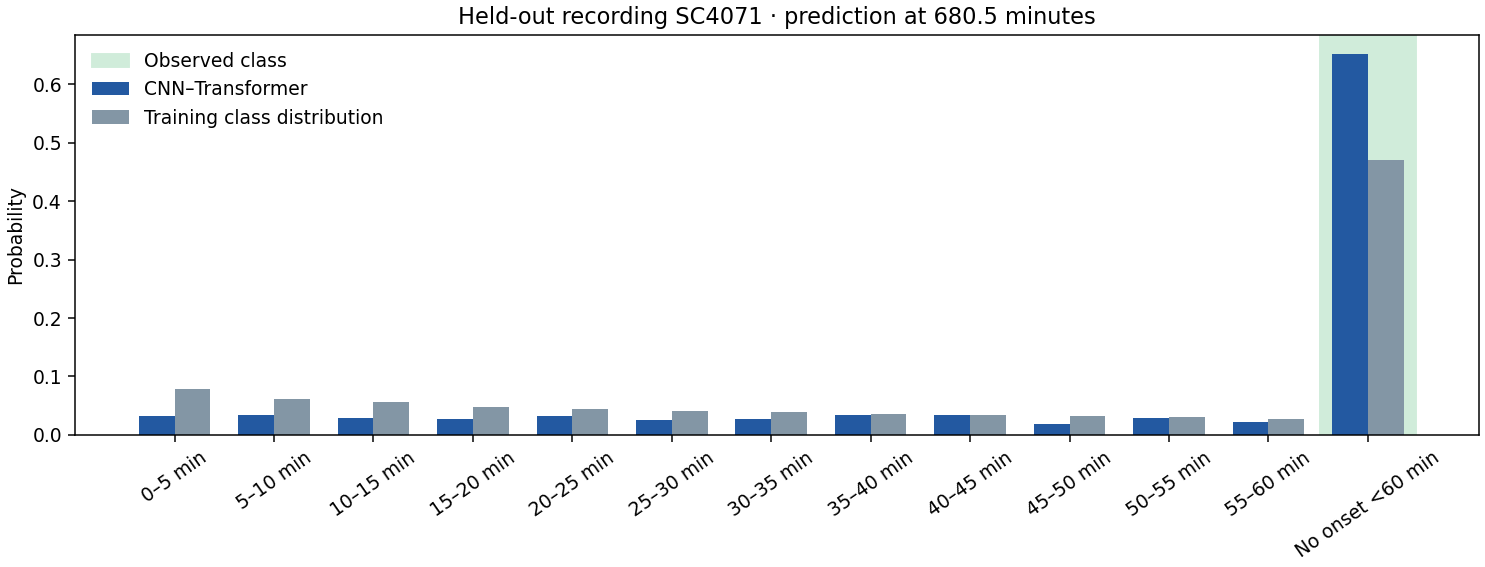

In [8]:
results, forecast_figure = evaluate_test(data, checkpoint, OUTPUT_DIR, device)
print(f"Held-out test split: {results['subjects']} people across {results['recordings']} recordings")
print(f"State: {results['state_epochs']:,} unique epochs "
      f"({results['state_short_history_epochs']:,} with short history)")
for name, scores in results["state"].items():
    print(f"  {name}: balanced accuracy {scores['balanced_accuracy']:.4f}, macro F1 {scores['macro_f1']:.4f}")
    print(f"  Confusion matrix (true rows, predicted columns, order Wake/Sleep): {scores['confusion_matrix']}")
print(f"Forecast: {results['forecast_windows']:,} windows, "
      f"{results['test_awakenings_within_hour']:,} observed onsets within the hour")
for name, scores in results["forecast"].items():
    print(f"  {name}: multiclass log loss {scores['multiclass_log_loss']:.4f}, "
          f"within-hour Brier {scores['within_hour_brier']:.4f}")
example = results["plot_example"]
print(f"Plot example: {example['record_id']}, end {example['window_end_sec']} s, "
      f"target {CLASS_LABELS[example['observed_class']]}")
display(forecast_figure)
plt.close(forecast_figure)

## 5. Export files for the Streamlit demo

Keep `best_checkpoint.pt` and `demo_windows.npz` in the `artifacts` folder next to `demo.py`, `eeg_data.py`, and `eeg_model.py`. The checkpoint includes training means and scales. The examples file includes raw feature histories from three held-out recordings. It carries the archive fingerprint used by the checkpoint. The demo takes a completed five-minute feature window, displays ten sleep probabilities, and displays the 13 forecast probabilities when the final epoch is classified as asleep.

Run `python -m pip install -r requirements.txt` and `python -m streamlit run demo.py` locally. A prepared window can be provided as a `(10, 11)` numeric `.npy` or a headerless `.csv` with the archive’s feature order. Download `training_log.json`, `test_metrics.json`, and `heldout_forecast.png` to keep the evaluation outputs.


In [9]:
export_demo_windows(data, training_log["archive_sha256"], OUTPUT_DIR / "demo_windows.npz")
print("Feature order:", ", ".join(FEATURE_NAMES))
print("Outputs:", ", ".join(sorted(path.name for path in OUTPUT_DIR.iterdir() if path.is_file())))

Exported 1,659 EEG windows from 3 held-out recordings to artifacts\demo_windows.npz
Feature order: delta_log_power, theta_log_power, alpha_log_power, sigma_log_power, beta_log_power, delta_relative_power, theta_relative_power, alpha_relative_power, sigma_relative_power, beta_relative_power, log_rms
Outputs: best_checkpoint.pt, demo_windows.npz, heldout_forecast.png, test_metrics.json, training_log.json
